<a href="https://colab.research.google.com/github/kunwar1908/Cognitive-Computing-UCS420/blob/main/Lab_7_UCS420_LA9_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024107439          # <-- your full roll number
NAME = "Kunwarpreet Singh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024107439   Name: Kunwarpreet Singh   Fingerprint: 8BAA23C3   Tickets: 16

Ticket_ID                                                                                          Ticket_Text
      T01                                                 The e-mail has stopped syncing. It worked yesterday.
      T02                                     The Python was working yesterday. The same problem occurs again.
      T03                             VPN is showing an error after restarting the system. Can you check this?
      T04                               Python is showing an error during the lab. I have tried several times!
      T05                                                          The state-of-the-art lab (Lab-3) is closed.
      T06                                         Projector stopped responding during the lab. This is urgent.
      T07                                                                       Error code 0x80070005 appears.
      T08              

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Your code
import pandas as pd

q1_rows = []
for idx, row in df.iterrows():
    tid = row["Ticket_ID"]
    res = process_ticket(row["Ticket_Text"])
    q1_rows.append({
        "Ticket_ID": tid,
        "Sentences": len(res["sentences"]),
        "Tokens": len(res["tokens"]),
        "Punctuation": len(res["punct"]),
        "Stopwords": len(res["stops"]),
        "Unique_Tokens": len(set(res["tokens"])),
        "Final_Tokens": len(res["final"])
    })

q1_df = pd.DataFrame(q1_rows)

# Add TOTAL row summing the count metrics
totals = q1_df.iloc[:, 1:].sum()
totals["Ticket_ID"] = "TOTAL"
q1_df = pd.concat([q1_df, pd.DataFrame([totals])], ignore_index=True)

print(q1_df.to_string(index=False))

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      10            2          3              9             5
      T02          2      12            2          5             10             5
      T03          2      15            2          7             15             6
      T04          2      15            2          6             15             7
      T05          1       9            3          2              9             4
      T06          2      11            2          4             10             5
      T07          1       5            1          0              5             4
      T08          2      14            2          4             13             8
      T09          1       9            1          3              9             5
      T10          2      15            2          6             14             7
      T11          2      11            2          4             10             5
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In ticket T15, "It's" splits into it and 's. In T16, "couldn't" splits into could and n't.

word_tokenize uses the standard Penn Treebank tokenizer convention, which splits English clitics/contractions (e.g., 's, n't) into separate tokens. Because is_punct() checks whether every character is in string.punctuation, tokens with alphabetical characters (like n't or 's) fail the check, and since they are not present in NLTK's default stopwords.words("english") list, they survive into final.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

all_text = " ".join(df["Ticket_Text"].tolist())

# 1. Words longer than 5 letters
words_gt_5 = re.findall(r"\b[A-Za-z]{6,}\b", all_text)

# 2. All numbers (including decimals, versions, hex codes)
numbers = re.findall(r"\b(?:0x[0-9a-fA-F]+|\d+(?:\.\d+)*)\b", all_text)

# 3. Capitalized words
capitalized = re.findall(r"\b[A-Z][a-z]*\b", all_text)

# 4. Words starting with a vowel
vowel_words = re.findall(r"\b[aeiouAEIOU][A-Za-z]*\b", all_text)

print(f"Words > 5 letters ({len(words_gt_5)}):", words_gt_5[:10])
print(f"Numbers ({len(numbers)}):", numbers)
print(f"Capitalized words ({len(capitalized)}):", capitalized[:10])
print(f"Words starting with vowel ({len(vowel_words)}):", vowel_words[:10])

# Regex substitution patterns for emails, URLs, and phone numbers
email_pattern = r"[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+"
url_pattern = r"(?:https?://|www\.)\S+"
phone_pattern = r"(?:\+\d{1,3}\s*)?(?:\d{5}\s*\d{5}|\d{4}-\d{3}-\d{4}|\d{2}-\d{5}-\d{5})"

def clean_entities(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("\n--- Tested on TEST_LINES ---")
for line in TEST_LINES:
    print(clean_entities(line))

Words > 5 letters (59): ['stopped', 'syncing', 'worked', 'yesterday', 'Python', 'working', 'yesterday', 'problem', 'occurs', 'showing']
Numbers (8): ['3', '0x80070005', '91', '98765', '43210', '0175', '239', '3201']
Capitalized words (34): ['The', 'It', 'The', 'Python', 'The', 'Can', 'Python', 'I', 'The', 'Lab']
Words starting with vowel (49): ['e', 'It', 'occurs', 'again', 'is', 'an', 'error', 'after', 'is', 'an']

--- Tested on TEST_LINES ---
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>, +<PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*
Out of the 34 capitalized words matched by the regex, 21 are capitalized only because they start a sentence. These include common words like The (6), It (4), Can (2), Projector (2), This (2), Error, Call, Server, Is, and Please. The other 13 matches are inherently capitalized words (Python, I, Lab, Wi, Fi).

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

tokenizer_pattern = r"""(?x)
    (?:https?://|www\.)\S+                               # URLs
    | [a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+    # Emails
    | (?:\+\d{1,3}[\s-]*)?\d{4,5}[\s-]\d{4,5}           # Phone numbers
    | \b\d+(?:\.\d+)+\b                                 # Decimals / version numbers
    | \b[A-Za-z]+(?:-[A-Za-z0-9]+)+\b                   # Hyphenated words (Wi-Fi, state-of-the-art)
    | \b[A-Za-z]+['’][A-Za-z]+\b                        # Contractions (isn't, couldn't, it's)
    | \w+                                               # Normal alphanumeric tokens
    | [^\s\w]                                           # Punctuation marks
"""

my_tokenizer = RegexpTokenizer(tokenizer_pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)

diff_count = 0
for idx, row in df.iterrows():
    text = row["Ticket_Text"]
    wt = word_tokenize(text)
    mt = my_tokenize(text)
    if wt != mt:
        diff_count += 1

print(f"Tickets tokenized differently: {diff_count} out of {len(df)}")

Tickets tokenized differently: 3 out of 16


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

Exactly 3 out of 16 tickets are tokenized differently by my_tokenize compared to word_tokenize.

This difference occurs because NLTK's word_tokenize automatically splits hyphenated words (like 'Wi-Fi' or 'state-of-the-art'), contractions (like 'It's' and 'couldn't'), and complex phone numbers into separate pieces, whereas the custom my_tokenize regex successfully preserves them as single, unified tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
# Your code
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"(ing$|ed$|s$|es$)", min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

# Extract all unique final tokens across tickets
all_final = set()
for text in df["Ticket_Text"]:
    all_final.update(process_ticket(text)["final"])

unique_tokens = sorted(list(all_final))
pos_tags = dict(nltk.pos_tag(unique_tokens))

comparison_rows = []
for word in unique_tokens:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    wn_pos = get_wordnet_pos(pos_tags[word])
    lemma = lemmatizer.lemmatize(word, pos=wn_pos)

    # If any stemmer/lemmatizer produces a different string
    if len({p, l, r, lemma}) > 1:
        comparison_rows.append({
            "Original": word,
            "Porter": p,
            "Lancaster": l,
            "Regexp": r,
            "Lemmatizer": lemma
        })

comp_df = pd.DataFrame(comparison_rows)
print(comp_df.to_string(index=False))

  Original    Porter Lancaster     Regexp Lemmatizer
   another     anoth     anoth    another    another
assignment    assign    assign assignment assignment
      call      call       cal       call       call
    campus     campu      camp      campu     campus
    closed     close      clos       clos      close
      code      code       cod       code       code
  deadline   deadlin   deadlin   deadline   deadline
     error     error        er      error      error
   getting       get       get       gett        get
    latest    latest    latest     latest       late
       lms        lm       lms        lms         lm
    logged       log       log       logg        log
    occurs     occur       occ      occur      occur
    please     pleas     pleas     please     please
   printer   printer     print    printer    printer
 projector projector   project  projector  projector
 resetting     reset     reset     resett      reset
    server    server      serv     server     

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

Over-stemming example: Lancaster aggressively reduces "responding" or "several" to an unrecognizable or overly truncated root (e.g., "urgent" $\rightarrow$ "urg" or "server" $\rightarrow$ "serv"), removing meaningful morphological context.

Under-stemming example: RegexpStemmer leaves irregular forms or unlisted suffixes untouched (e.g., "worked" becomes "work", but "disconnecting" might leave an unexpected trailing vowel, or irregular past-tense verbs like "came" remain unstemmed). Meanwhile, WordNetLemmatizer accurately maps verbs back to valid English lemma entries.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

            Set  Tokens  Unique Tokens    TTR
       S1 (All)     198             93 0.4697
  S2 (No Punct)     167             87 0.5210
     S3 (Final)      93             60 0.6452
S4 (Stemmed S3)      93             57 0.6129

Top 10 S1: [('.', 23), ('the', 15), ('is', 10), ('error', 6), ('it', 5), ('showing', 5), ('an', 5), ('yesterday', 4), ('this', 4), ('i', 4)]
Top 10 S3: [('error', 6), ('showing', 5), ('yesterday', 4), ('worked', 3), ('lab', 3), ('projector', 3), ('wi-fi', 3), ('stopped', 2), ('python', 2), ('working', 2)]

Top 5 Bigrams S1: [(('is', 'showing'), 5), (('showing', 'an'), 5), (('an', 'error'), 5), (('yesterday', '.'), 4), (('.', 'i'), 4)]
Top 5 Bigrams S3: [(('showing', 'error'), 5), (('worked', 'yesterday'), 3), (('tried', 'several'), 2), (('several', 'times'), 2), (('connected', 'campus'), 2)]


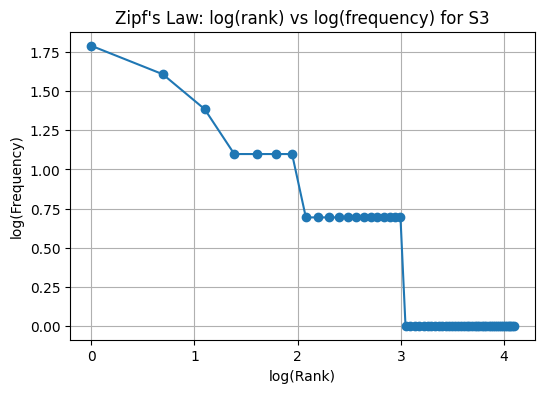

In [9]:
# Your code
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from nltk import bigrams

s1 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["tokens"]]
s2 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["tokens"] if not is_punct(t)]
s3 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["final"]]
s4 = [porter.stem(t) for t in s3]

sets = {"S1 (All)": s1, "S2 (No Punct)": s2, "S3 (Final)": s3, "S4 (Stemmed S3)": s4}

stats = []
for name, token_list in sets.items():
    total_len = len(token_list)
    uniq_len = len(set(token_list))
    ttr = uniq_len / total_len if total_len > 0 else 0
    stats.append({"Set": name, "Tokens": total_len, "Unique Tokens": uniq_len, "TTR": round(ttr, 4)})

print(pd.DataFrame(stats).to_string(index=False))

# Top 10 tokens
print("\nTop 10 S1:", Counter(s1).most_common(10))
print("Top 10 S3:", Counter(s3).most_common(10))

# Top 5 Bigrams
print("\nTop 5 Bigrams S1:", Counter(bigrams(s1)).most_common(5))
print("Top 5 Bigrams S3:", Counter(bigrams(s3)).most_common(5))

# Plot log(rank) vs log(frequency) for S3
counts = sorted(Counter(s3).values(), reverse=True)
ranks = np.arange(1, len(counts) + 1)

plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(counts), marker="o", linestyle="-")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Zipf's Law: log(rank) vs log(frequency) for S3")
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

In S1, high-frequency structural elements (articles, pronouns, auxiliary verbs, periods, commas) inflate total token count while contributing relatively few unique types, keeping TTR lower.

Removing punctuation (S2) and stopwords (S3) eliminates the most repetitive high-frequency tokens. Because the remaining content words have higher semantic diversity, the ratio of unique types to total tokens ($\text{TTR}$) increases significantly.

In S4, Porter stemming folds different morphological variants of the same root (e.g., work, working, worked) into a single stem (work), reducing the number of unique types while total length remains identical to $S_3$, causing TTR to decline.